# Bike Sharing Predictive Analysis
**By Anshuman · Next-day hourly demand forecasting**

One row is one system-wide hour; the regression target is `cnt`, observed rental trips.
At **11:59 PM on the previous calendar day**, forecast all **24 hourly counts for the next day**
(a lead time of about 1 minute to 23 hours 1 minute to hourly slot starts).
A hypothetical operations manager currently uses last week's same-hour rentals to plan aggregate
service capacity and staffing; we compare that rule with machine learning. These data cannot allocate
bikes to individual stations, and observed trips do not measure unmet demand.

Primary metric: **MAE in rentals/hour**; secondary: RMSE. No random time-series splitting.
This is a historical rolling-origin evaluation, not a claim of deployment.

## 1. Real data and audit
The public UCI `hour.csv` is the source, never a synthetic fallback. The single Python entry point verifies its SHA-256 checksum. Only hourly observations are used; future daily aggregates are excluded. The full hourly grid exposes missing records; **missing target values stay NaN**.
The audit covers the whole file to define coverage and split dates. EDA used to understand modeling
patterns is restricted to the proper fitting period, before calibration and testing.

In [1]:
from pathlib import Path
import os, sys
# Limit nested numeric parallelism for reproducible, modest CPU use.
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
os.environ.setdefault('MPLCONFIGDIR', '/tmp/bike-mpl')
# Google Colab setup uses this same notebook and the shared Python package.
if 'google.colab' in sys.modules:
    import subprocess
    checkout = Path('/content/bike-sharing-portfolio')
    if not checkout.exists():
        subprocess.run(['git', 'clone', '--depth', '1',
                        'https://github.com/agrawalanshuman/Bike_Sharing_Predictive_Analysis.git',
                        str(checkout)], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    '-r', str(checkout / 'requirements-gurobi.txt')], check=True)
    os.chdir(checkout)
ROOT = Path.cwd()
if not (ROOT / 'bike_sharing.py').exists() and (ROOT.parent / 'bike_sharing.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'bike_sharing.py').exists():
    raise RuntimeError('Run this notebook from the repository root; see README for setup steps.')
sys.path.insert(0, str(ROOT))
import json, numpy as np, pandas as pd
from IPython.display import display, Markdown, Image
from bike_sharing import (prepare, fit_first, run_advanced, save_results,
                             score, FEATURES, NUMERIC, CATEGORICAL, issue_times)
from bike_sharing import eda, evaluation_plots, explain_cases, business_plot
pd.set_option('display.max_columns', 20)
(ROOT / 'reports').mkdir(exist_ok=True)
d = prepare()
print(json.dumps(d['audit'], indent=2))

{
  "source_rows": 17379,
  "source_columns": 17,
  "source_start": "2011-01-01 00:00:00",
  "source_end": "2012-12-31 23:00:00",
  "full_grid_hours": 17544,
  "missing_hours": 165,
  "sha256_hour_csv": "e03de4ee4ef4dc376ac6e04bf829673c6269e8eba5c60fa121640fa2f829504f",
  "fit_start": "2011-01-08 23:00:00",
  "fit_end": "2012-10-07 23:00:00",
  "fit_rows": 15195,
  "calibration_start": "2012-10-08 00:00:00",
  "calibration_end": "2012-11-04 23:00:00",
  "calibration_rows": 636,
  "test_start": "2012-11-05 00:00:00",
  "test_end": "2012-12-30 23:00:00",
  "test_rows": 1302,
  "test_scheduled_hours": 1344,
  "test_missing_actuals": 4,
  "test_missing_week_lag_with_actual": 38,
  "terminal_hours_not_tested": 24
}


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
timestamp,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
2011-01-01 01:00:00,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2011-01-01 02:00:00,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
2011-01-01 03:00:00,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
2011-01-01 04:00:00,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


,dtype
instant,int64
dteday,object
season,int64
yr,int64
mnth,int64
hr,int64
holiday,int64
weekday,int64
workingday,int64
weathersit,int64


,Full-source target distribution
count,17379.000000
mean,189.463088
std,181.387599
min,1.000000
25%,40.000000
50%,142.000000
75%,281.000000
max,977.000000


Duplicate timestamps: 0
Original missing cells: 0


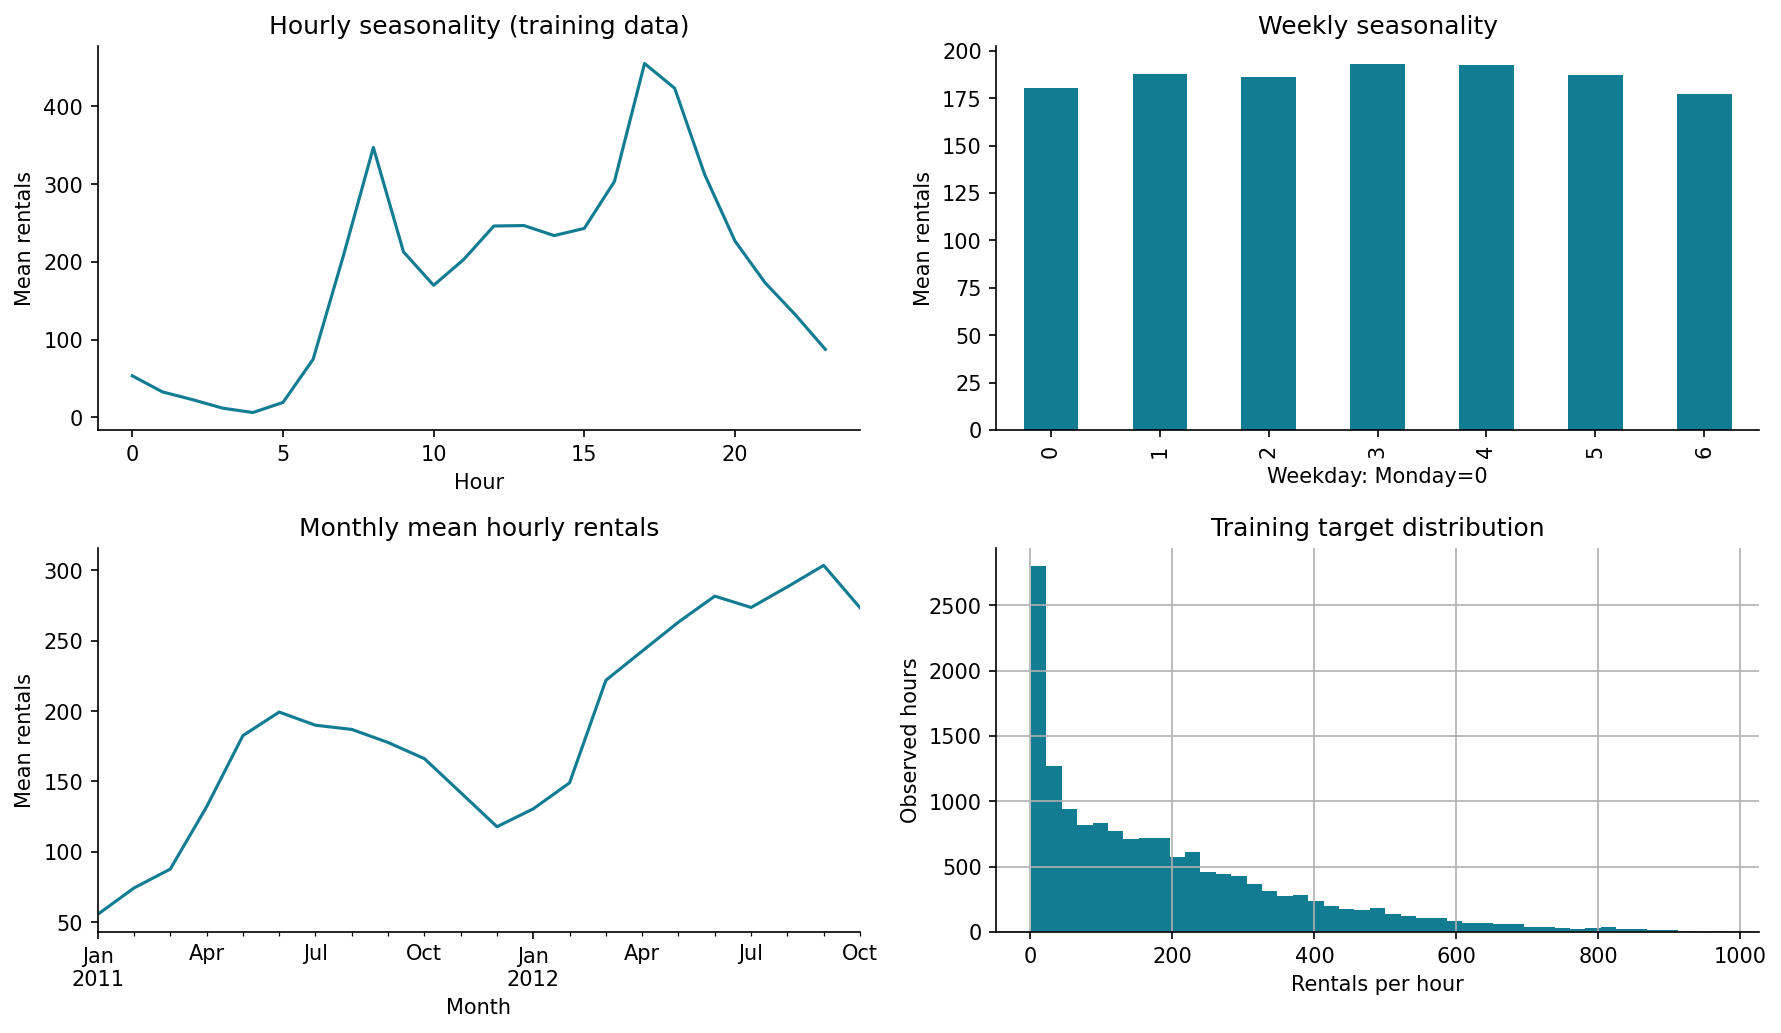

In [2]:
display(d['raw'].head())
display(d['raw'].dtypes.rename('dtype').to_frame())
display(d['raw']['cnt'].describe().to_frame('Full-source target distribution'))
print('Duplicate timestamps:', d['raw'].index.duplicated().sum())
print('Original missing cells:', int(d['raw'].isna().sum().sum()))
display(Image(filename=str(eda(d))))

## 2. Leakage audit and forecast-time availability
| Raw columns | Treatment and reason |
|---|---|
| `cnt` | Target only. Never a contemporaneous feature. |
| `casual`, `registered` | Excluded: components whose sum is `cnt`. |
| `temp`, `atemp`, `hum`, `windspeed`, `weathersit` | Excluded: observed at the future target hour; no historical forecast archive exists here. No future-aware interpolation. |
| `instant` | Excluded: arbitrary row identifier. |
| `dteday` | Index construction only, not a raw predictor. |
| `hr`, `weekday`, `mnth`, `yr` | Replaced by explicitly derived hour, weekday, month, and elapsed calendar time. |
| `season` | Excluded: month captures known annual calendar information. Error slices use explicit meteorological seasons. |
| `holiday`, `workingday` | Calendar information assumed published before issuance; holiday is mapped by date, workingday recomputed from weekday and holiday. No target-dependent filling. |

`lag_24`, `lag_48`, `lag_168` reference the **exact timestamp**, including missing hours.
For a target at time t, seven-day mean, maximum, and observed count use the 168 slots
**[t − 191 hours, t − 24 hours]**. Means/maxima ignore missing historical observations; the count exposes
how much history was observed. Missing lag features are median-imputed inside each training pipeline.
No target is imputed for fitting or scoring.

All historical sources end no later than the previous day's same hour, hence before the common
11:59 PM issuance. Assuming that an hour's count is finalized by 11:59 PM that day is an explicit
operational assumption; a reporting delay would require an additional lag.
The calendar itself is known in advance. Tests perturb all target-day and later counts/weather and
check that all 24 forecast rows remain unchanged.

Engineered features include **lag_48**, **seven-day rolling maximum**,
**workday × commute-hour interaction**, and observed-history count. Cyclic hour features and a calendar
trend are also included. These choices were fixed before viewing test metrics; no feature was kept or
removed based on test performance.

In [3]:
display(d['X'].loc[d['fit'][:5]])
print('Features:', FEATURES)
for lag in (24,48,168):
    assert ((d['X'].index-pd.Timedelta(hours=lag)) < issue_times(d['X'].index)).all()
assert ((d['X'].index-pd.Timedelta(hours=24)) < issue_times(d['X'].index)).all()
print('All lag and rolling-window end timestamps precede daily issuance.')

,hour,dow,month,holiday,workingday,lag_24,lag_48,lag_168,roll_mean_7d,roll_max_7d,roll_count_7d,commute_workday,hour_sin,hour_cos,trend_days
timestamp,,,,,,,,,,,,,,,
2011-01-08 23:00:00,23,5,1,0.0,0,15.0,23.0,39.0,58.465839,219.0,161.0,0,-0.258819,0.965926,7.958333
2011-01-09 00:00:00,0,6,1,0.0,0,25.0,17.0,17.0,58.521739,219.0,161.0,0,0.000000,1.000000,8.000000
2011-01-09 01:00:00,1,6,1,0.0,0,16.0,7.0,17.0,58.372671,219.0,161.0,0,0.258819,0.965926,8.041667
2011-01-09 02:00:00,2,6,1,0.0,0,16.0,1.0,9.0,58.273292,219.0,161.0,0,0.500000,0.866025,8.083333
2011-01-09 03:00:00,3,6,1,0.0,0,7.0,NaN,6.0,58.236025,219.0,161.0,0,0.707107,0.707107,8.125000


Features: ['hour', 'dow', 'month', 'holiday', 'workingday', 'lag_24', 'lag_48', 'lag_168', 'roll_mean_7d', 'roll_max_7d', 'roll_count_7d', 'commute_workday', 'hour_sin', 'hour_cos', 'trend_days']
All lag and rolling-window end timestamps precede daily issuance.


## 3. Chronological splitting and evaluation contract
The last **eight complete Monday–Sunday calendar weeks** are the held-out test window.
December 31 is a partial terminal week and is not used for model selection or testing.
Four preceding weeks are reserved exclusively for conformal calibration. The baseline and advanced
models share this split so their results remain comparable. All earlier observed rows after the fixed
191-hour history warm-up train both models. Dates and row counts are printed below.

All methods are scored on **identical observed target hours with an observed 168-hour lag**.
Missing baseline references cause exclusion from the common metric sample; they are never fabricated.
This can bias evaluation toward hours with good history and is a stated limitation. Models can still
forecast all 24 hours using train-only imputation; only scoring requires observed targets and baseline.

The fitted model is frozen through calibration and testing. For each next day, past test-day observations
may refresh lag features after they have actually occurred. This is rolling-origin **daily feature
updating**, not a single 56-day forecast and not test-target fitting. No current-day count is used in
any of that day's 24 forecasts.

In [4]:
display(pd.Series(d['audit']).to_frame('Value'))
print('No overlap:', d['fit'].max() < d['cal'].min() < d['test'].min())
print('Scheduled test hours:', d['audit']['test_scheduled_hours'])
print('Missing actuals excluded:', d['audit']['test_missing_actuals'])
print('Missing baseline with observed target excluded:', d['audit']['test_missing_week_lag_with_actual'])

,Value
source_rows,17379
source_columns,17
source_start,2011-01-01 00:00:00
source_end,2012-12-31 23:00:00
full_grid_hours,17544
missing_hours,165
sha256_hour_csv,e03de4ee4ef4dc376ac6e04bf829673c6269e8eba5c60f...
fit_start,2011-01-08 23:00:00
fit_end,2012-10-07 23:00:00
fit_rows,15195


No overlap: True
Scheduled test hours: 1344
Missing actuals excluded: 4
Missing baseline with observed target excluded: 38


## 4. Seasonal baseline and first regression
The baseline is the observed count exactly 168 hours earlier. Ridge regression (`alpha=10`, fixed in
advance) uses a `ColumnTransformer` plus `Pipeline`: median imputation and scaling for numeric features,
one-hot calendar encoding with unknown-category handling, then regression. Every fitted transformation
sees proper training only. Negative predictions are clipped to zero as a prespecified physical constraint.

In [5]:
ridge_model, ridge_pred = fit_first(d)
first_predictions = pd.DataFrame({'actual': d['y'].loc[d['test']],
    'seasonal_naive': d['X'].loc[d['test'], 'lag_168'], 'ridge': ridge_pred})
first_metrics = pd.DataFrame({name: score(first_predictions.actual, first_predictions[name])
                              for name in ['seasonal_naive','ridge']}).T
gain = first_metrics.loc['seasonal_naive','MAE']-first_metrics.loc['ridge','MAE']
display(first_metrics)
print(f'Ridge absolute MAE improvement: {gain:.3f} rentals/hour; percentage: {100*gain/first_metrics.iloc[0].MAE:.2f}%')
print(ridge_model)
# A genuine daily API issues 24 forecasts from strictly prior-day history.
from bike_sharing import forecast_day
first_day = d['test'][0].normalize()
daily_forecast = forecast_day(ridge_model, d['grid'], first_day, holiday=int(d['grid'].loc[first_day, 'holiday']))
assert len(daily_forecast) == 24
display(daily_forecast)
first_metrics.to_csv(ROOT/'results/baseline_metrics.csv')

,MAE,RMSE
seasonal_naive,71.948541,119.503996
ridge,64.104873,96.101284


Ridge absolute MAE improvement: 7.844 rentals/hour; percentage: 10.90%
Pipeline(steps=[('prep',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('numeric',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['lag_24', 'lag_48',
                                                   'lag_168', 'roll_mean_7d',
                                                   'roll_max_7d',
                                                   'roll_count_7d',
                                                   'commute_w

,forecast,seasonal_naive
timestamp,,
2012-11-05 00:00:00,68.916776,22.0
2012-11-05 01:00:00,98.711579,NaN
2012-11-05 02:00:00,65.109459,NaN
2012-11-05 03:00:00,54.853179,NaN
2012-11-05 04:00:00,52.105438,NaN
2012-11-05 05:00:00,58.106890,NaN
2012-11-05 06:00:00,77.775890,NaN
2012-11-05 07:00:00,154.949002,NaN
2012-11-05 08:00:00,217.705708,NaN


## 5. Held-out week and residuals
The plotted week is the first test week, specified in advance. All lines use the common scoring rows.

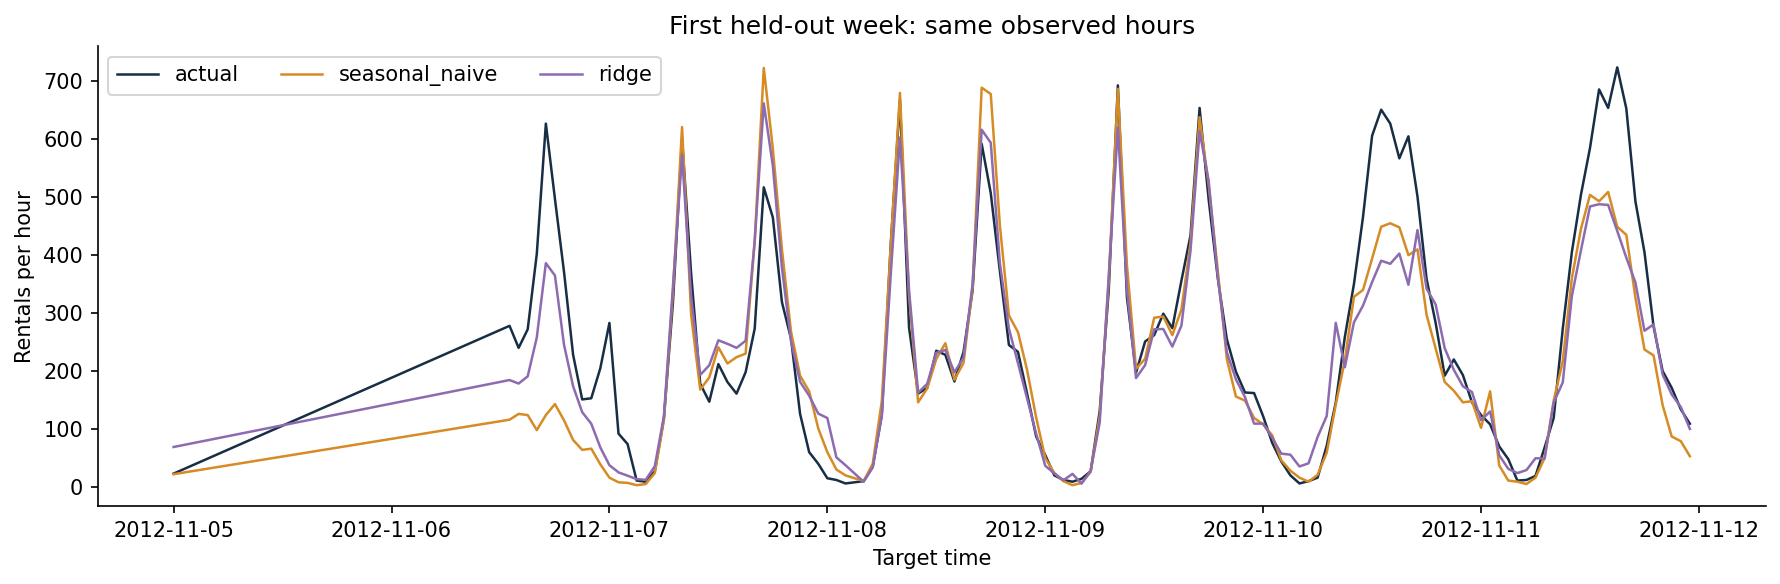

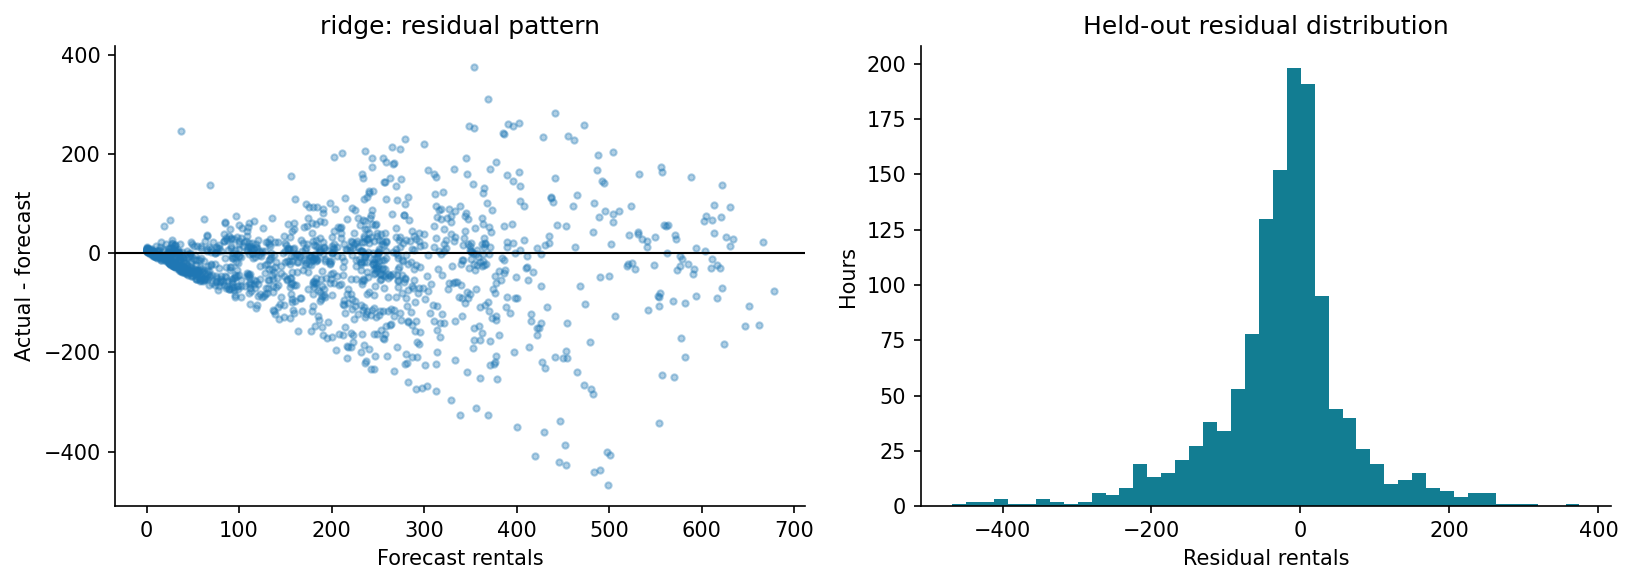

In [6]:
evaluation_plots(first_predictions)
display(Image(filename=str(ROOT/'visualizations/baseline_week.png')))
display(Image(filename=str(ROOT/'visualizations/baseline_residuals.png')))

## 6. Advanced model: tuning entirely inside proper training
HistGradientBoostingRegressor is tuned on three meaningful knobs: learning rate, leaf count, and L2
regularization. Eight seeded random configurations use three expanding chronological TimeSeriesSplit
folds. Each validation block has 672 observed rows; a 24-row gap conservatively keeps training labels
before the first validation day's issuance, even with missing hours. Folds may begin within a calendar
day because this is a row-based splitter; the availability assertion below ensures this is still safe.
No randomized early-stopping split is used (`early_stopping=False`, 220 iterations fixed in advance).
The winning configuration is chosen by mean validation MAE, refit on proper training, and frozen.
Calibration and test outcomes never choose hyperparameters. More complex does not guarantee better.

Selected parameters: {'model__max_leaf_nodes': 15, 'model__learning_rate': 0.08, 'model__l2_regularization': 10.0}
Mean proper-training CV MAE: 53.783997233467176


,train_end,validation_start,validation_end
0,2012-07-14 23:00:00,2012-07-16 00:00:00,2012-08-12 23:00:00
1,2012-08-11 23:00:00,2012-08-13 00:00:00,2012-09-09 23:00:00
2,2012-09-08 23:00:00,2012-09-10 00:00:00,2012-10-07 23:00:00


,params,mean_test_score,std_test_score,rank_test_score
4,"{'model__max_leaf_nodes': 15, 'model__learning...",-53.783997,6.402260,1
7,"{'model__max_leaf_nodes': 31, 'model__learning...",-54.873280,4.532968,2
0,"{'model__max_leaf_nodes': 47, 'model__learning...",-54.996646,7.421190,3
2,"{'model__max_leaf_nodes': 47, 'model__learning...",-55.548666,4.121406,4
1,"{'model__max_leaf_nodes': 47, 'model__learning...",-56.333301,5.405815,5
6,"{'model__max_leaf_nodes': 47, 'model__learning...",-58.160578,4.118797,6
3,"{'model__max_leaf_nodes': 47, 'model__learning...",-58.511970,5.987278,7
5,"{'model__max_leaf_nodes': 31, 'model__learning...",-58.813039,8.064636,8


,MAE,RMSE,MAE_improvement,MAE_improvement_pct
model,,,,
seasonal_naive,71.948541,119.503996,0.000000,0.000000
ridge,64.104873,96.101284,7.843668,10.901775
boosting,69.304928,108.417991,2.643613,3.674311


**Lowest test MAE: ridge.** These test results compare prespecified workflows; they were not used to retune any model. A deployment choice still requires a new pilot or holdout.

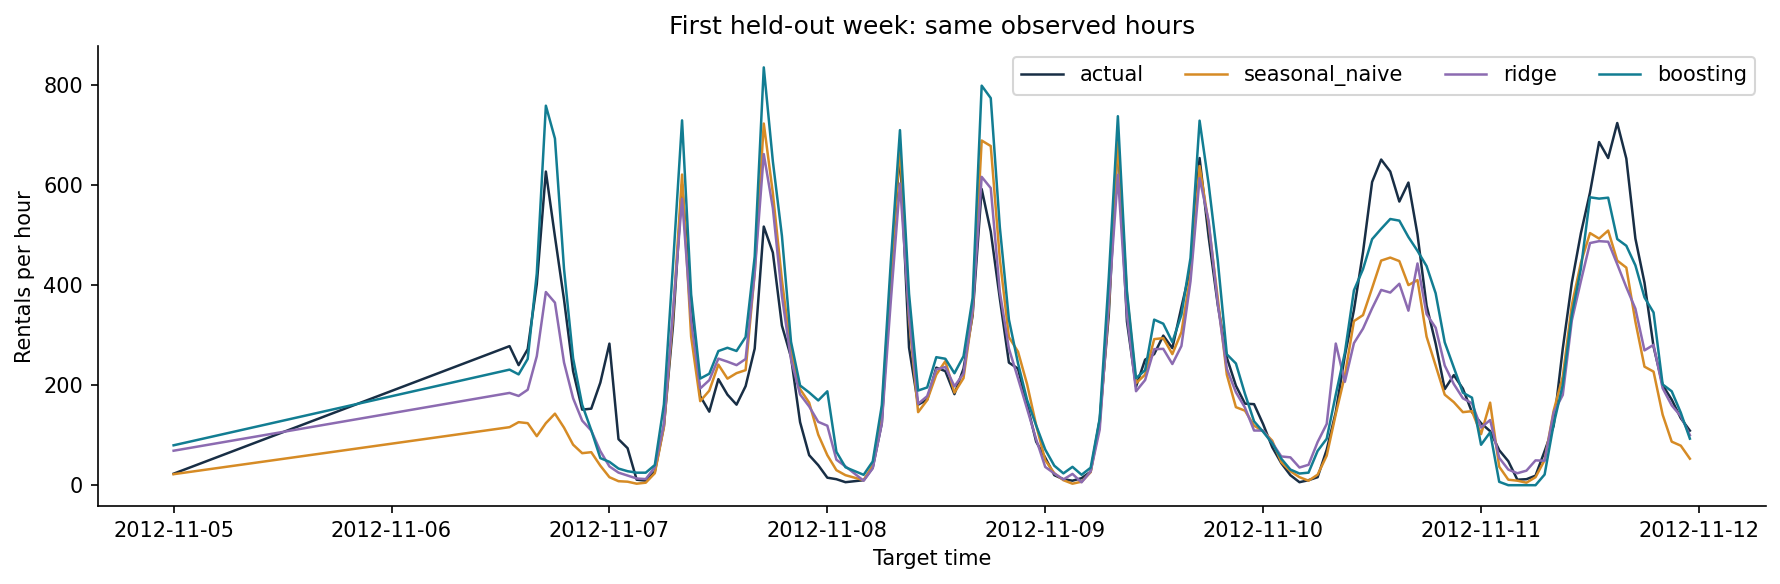

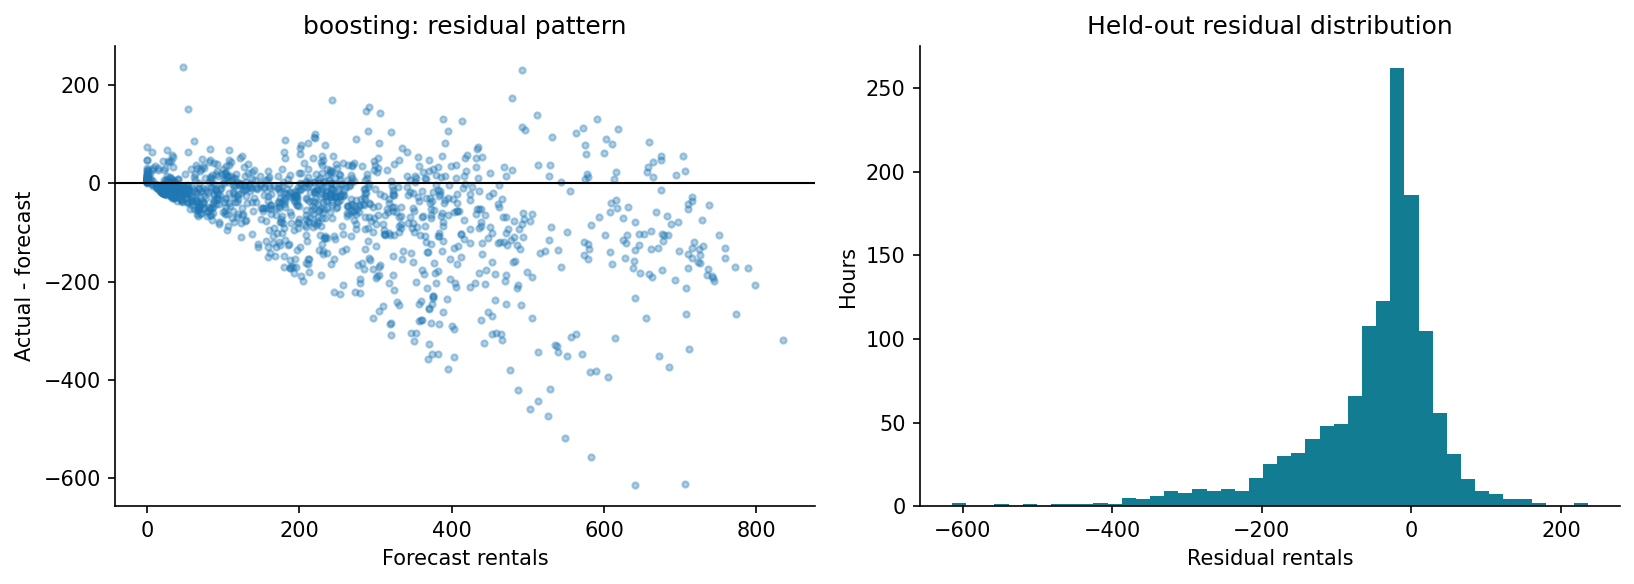

In [7]:
a = run_advanced(d, ridge_pred)
summary = save_results(d, a)
print('Selected parameters:', summary['best_params'])
print('Mean proper-training CV MAE:', summary['best_cv_MAE'])
display(pd.DataFrame(a['cv_boundaries']))
display(pd.DataFrame(a['search'].cv_results_)[['params','mean_test_score','std_test_score','rank_test_score']].sort_values('rank_test_score'))
display(a['metrics'])
best = a['metrics'].MAE.idxmin()
display(Markdown(f"**Lowest test MAE: {best}.** These test results compare prespecified workflows; they were not used to retune any model. A deployment choice still requires a new pilot or holdout."))
evaluation_plots(a['predictions'], a['slices'])
display(Image(filename=str(ROOT/'visualizations/actual_vs_predicted.png')))
display(Image(filename=str(ROOT/'visualizations/residuals.png')))

## 7. Regression prediction intervals with MAPIE
`SplitConformalRegressor(prefit=True, confidence_level=0.9)` calibrates the frozen tuned model on a
separate chronological four-week block. Nonnegative bounds are prespecified because rental counts
cannot be negative. No model refit occurs after calibration. Coverage is the fraction of held-out
actuals inside the interval, and width is measured in rentals/hour on the same common test sample.

Split conformal's usual marginal guarantee requires exchangeability. Serial dependence, changing
rental volumes, weather, and temporal distribution shift violate that assumption here. **90% is the
nominal target, not a guaranteed time-series or per-hour coverage claim.** Report the measured value,
including any shortfall; intervals are not a promise of station-level service capacity.

,Result
nominal_coverage,0.900000
empirical_coverage,0.856375
average_width,251.418978
calibration_rows,636.000000


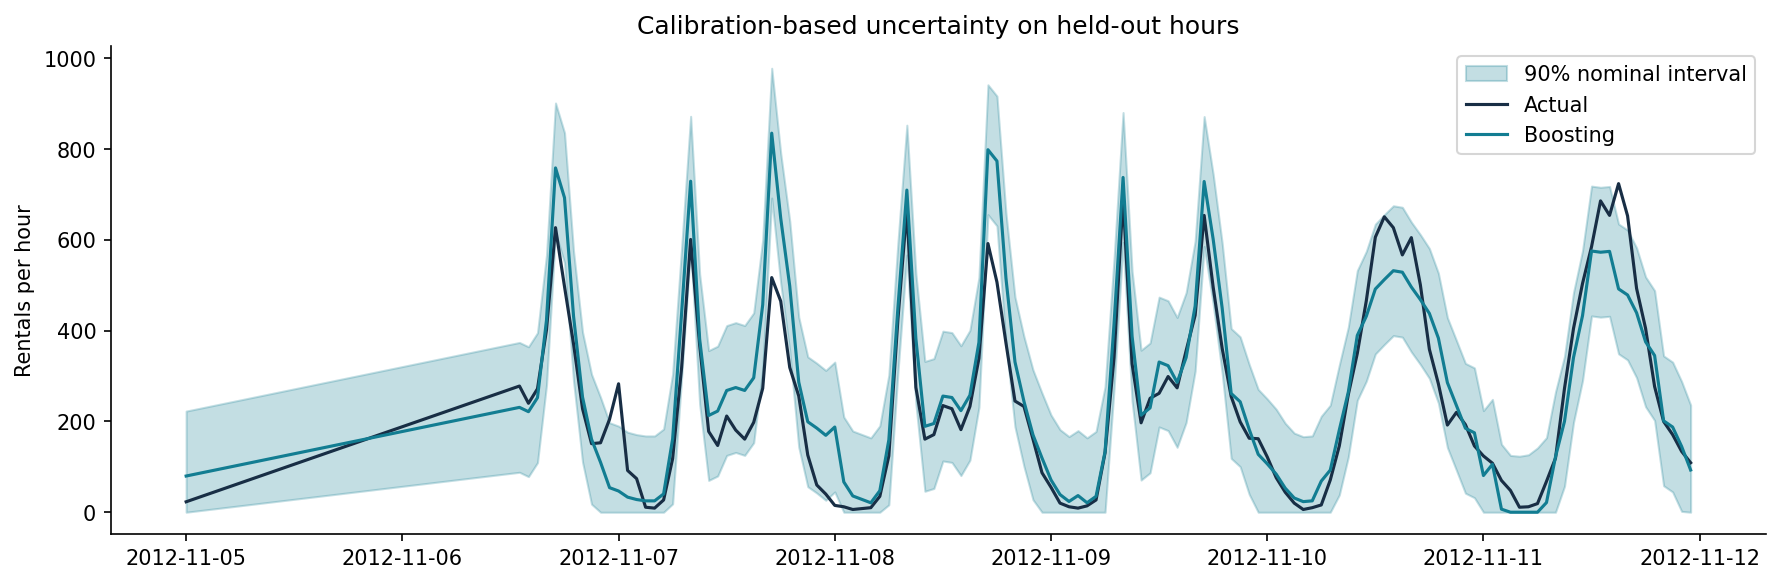

Observed coverage: 85.64%; nominal target: 90%; shortfall: 4.36% points.


In [8]:
display(pd.Series(a['intervals']).to_frame('Result'))
display(Image(filename=str(ROOT/'visualizations/intervals.png')))
coverage = a['intervals']['empirical_coverage']
print(f'Observed coverage: {coverage:.2%}; nominal target: 90%; shortfall: {max(0,.9-coverage):.2%} points.')

## 8. Three genuine SHAP waterfall explanations
Cases are selected by the lowest, median, and highest tuned-model forecast on common test hours,
not chosen for attractive outcomes. The fitted pipeline supplies the transformed feature names.
Tree SHAP values add to the **raw** model prediction; clipping any negative count to zero is a separate
physical rule. The additivity assertion checks each explanation. Correlated lags may share attribution;
these charts are model explanations, not causal analyses.

### Low demand: For the low-demand case at 2012-12-30 04:00:00, the model forecasts 0.0 rentals; the largest local contributions are lag_168 (-91.9 rentals) and lag_24 (-42.4 rentals). These inputs move this prediction relative to the model reference of 187.8 rentals; they describe the model's reasoning, not the causal effect of changing capacity or the calendar.

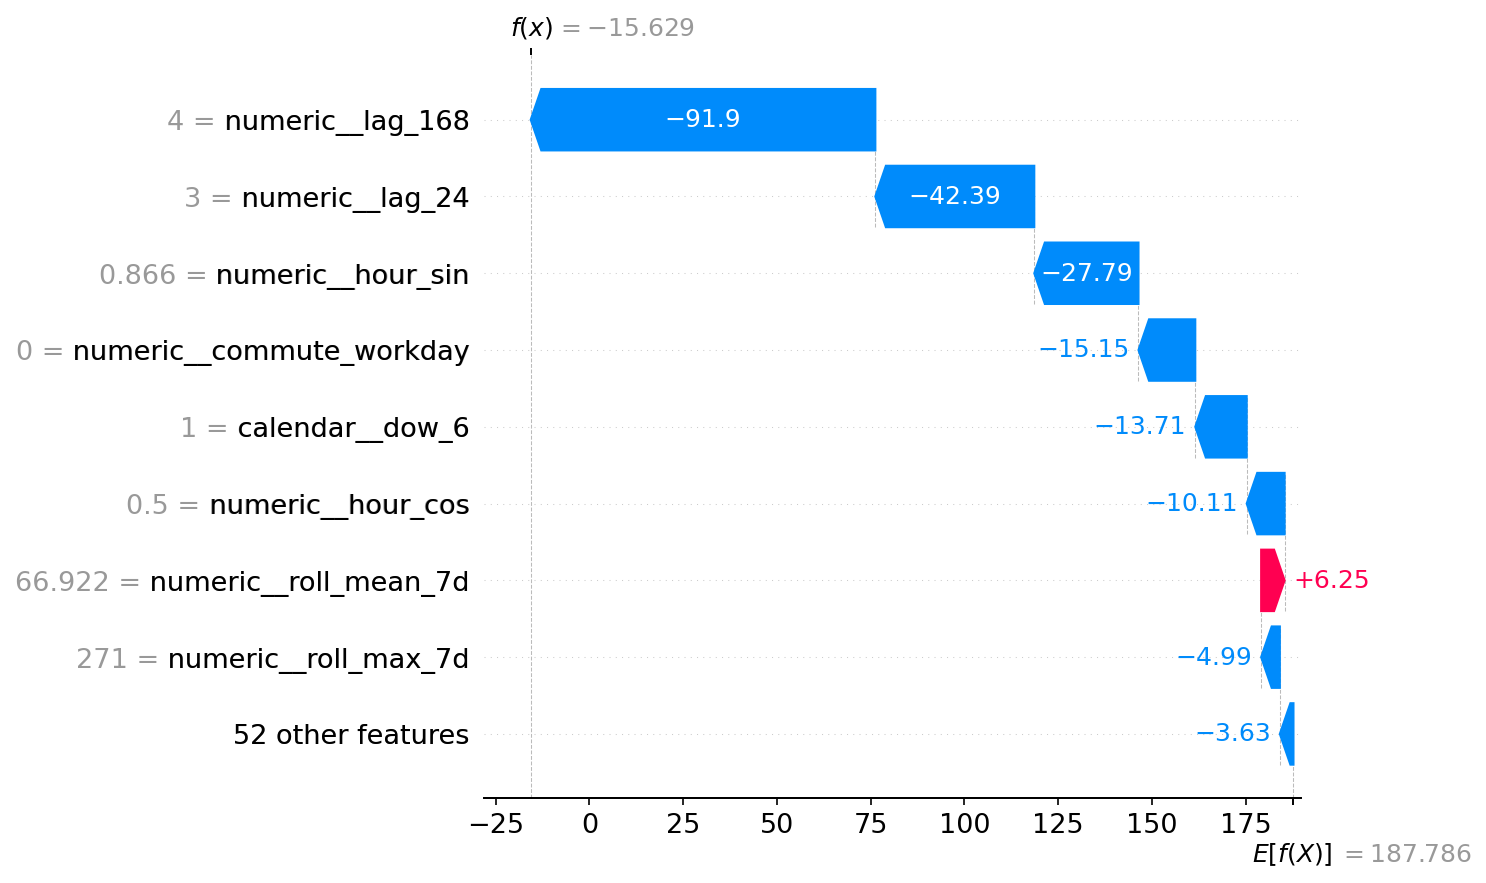

### Moderate demand: For the moderate-demand case at 2012-11-24 20:00:00, the model forecasts 212.2 rentals; the largest local contributions are trend_days (+42.4 rentals) and hour_sin (+23.6 rentals). These inputs move this prediction relative to the model reference of 187.8 rentals; they describe the model's reasoning, not the causal effect of changing capacity or the calendar.

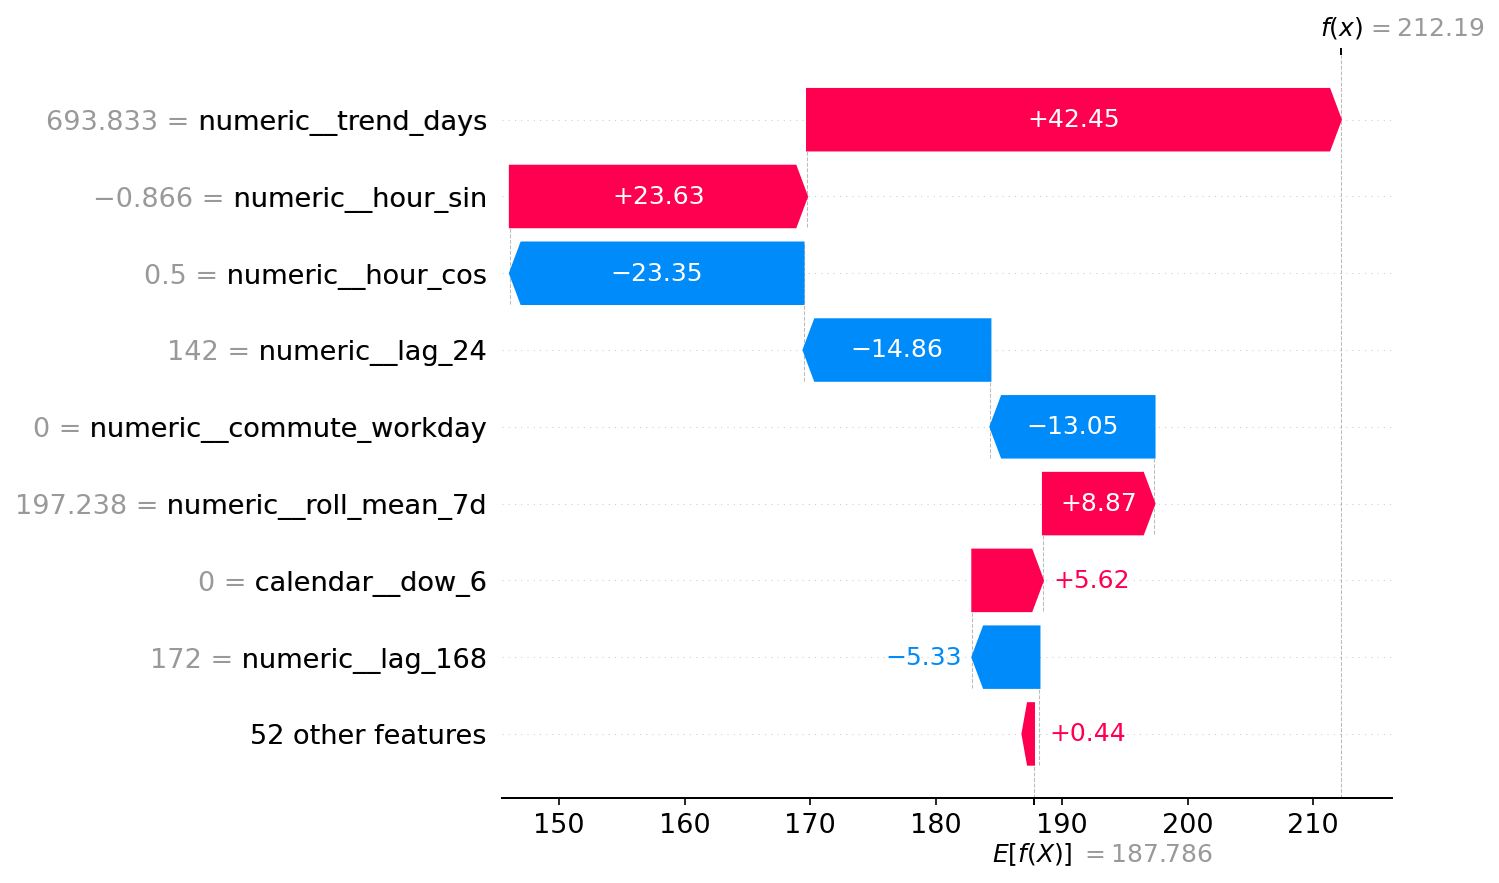

### High demand: For the high-demand case at 2012-11-07 17:00:00, the model forecasts 835.2 rentals; the largest local contributions are lag_168 (+280.1 rentals) and trend_days (+96.1 rentals). These inputs move this prediction relative to the model reference of 187.8 rentals; they describe the model's reasoning, not the causal effect of changing capacity or the calendar.

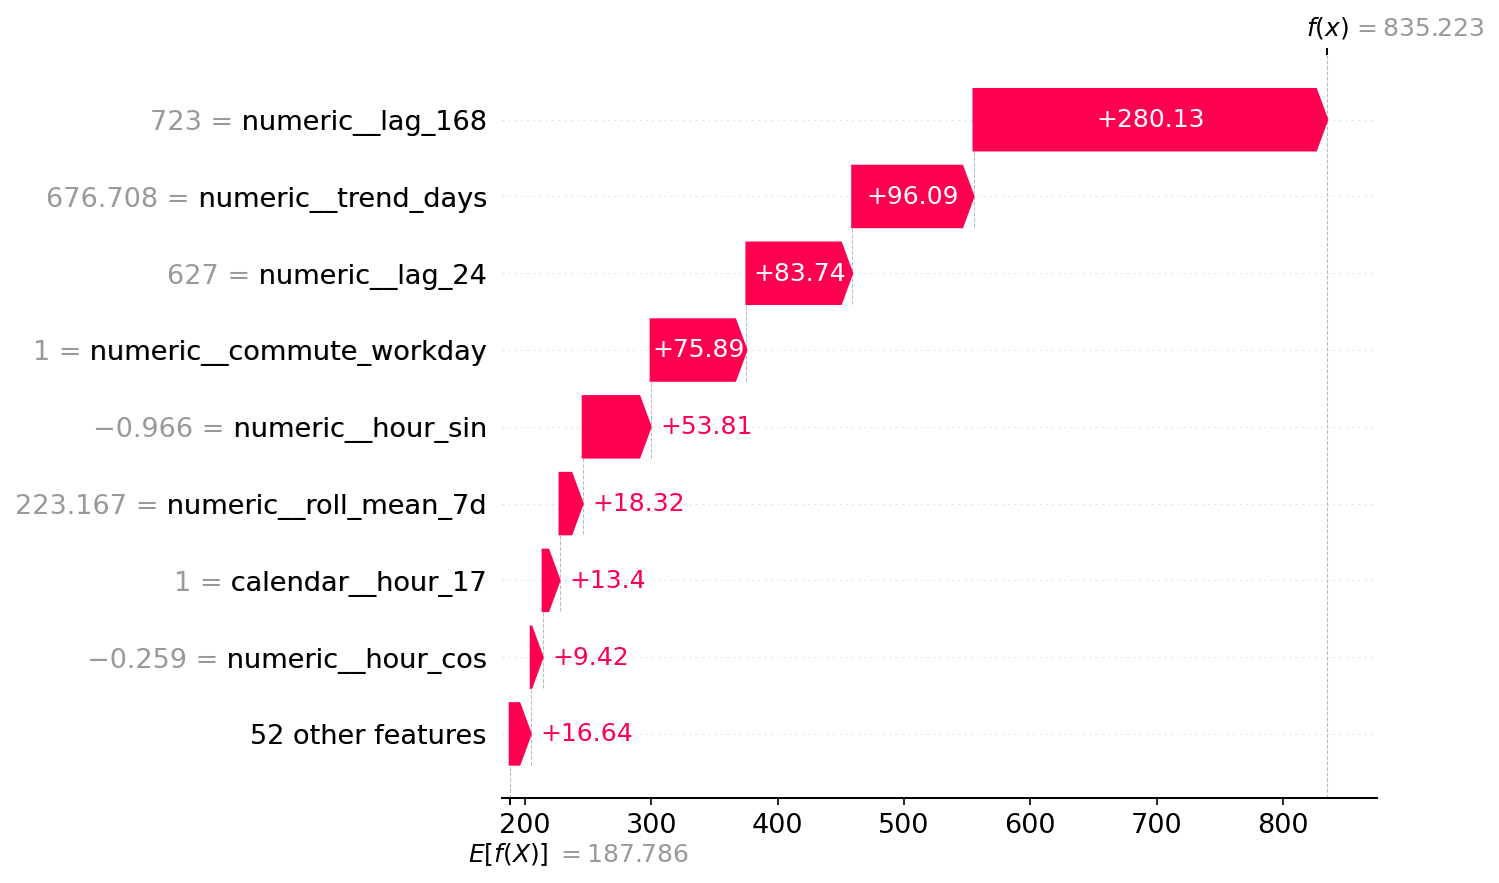

In [9]:
cases = explain_cases(a['model'], d, a['predictions'])
(ROOT/'results/shap_cases.json').write_text(json.dumps(cases, indent=2))
for case in cases:
    display(Markdown('### '+case['case'].title()+' demand: '+case['explanation']))
    display(Image(filename=str(ROOT/f"visualizations/shap_{case['case']}.png")))

## 9. Error slices
MAE and RMSE are computed by hour, commute/noncommute, weekday/weekend, meteorological season, and observed weather situation. Actual weather is used only for post-prediction error diagnosis; it is never a forecast input.
These test weeks contain autumn and winter only; no spring/summer generalization claim follows.
Small groups are noisy, and the worst subgroup is descriptive, not a new tuning target.

,dimension,slice,model,n,MAE,RMSE
0,hour,0,seasonal_naive,55,28.800000,58.280825
1,hour,0,ridge,55,33.378992,51.780502
2,hour,0,boosting,55,37.236878,58.866868
3,hour,1,seasonal_naive,54,18.407407,29.136333
4,hour,1,ridge,54,23.182970,30.060662
...,...,...,...,...,...,...
94,observed_weather,light rain/snow,ridge,92,130.371272,172.282547
95,observed_weather,light rain/snow,boosting,92,146.942292,197.874672
96,observed_weather,mist/cloudy,seasonal_naive,481,60.590437,105.894507
97,observed_weather,mist/cloudy,ridge,481,55.799333,83.386073


Worst boosting slice by MAE: **hour = 17**, n=55, MAE=174.65, RMSE=210.10.

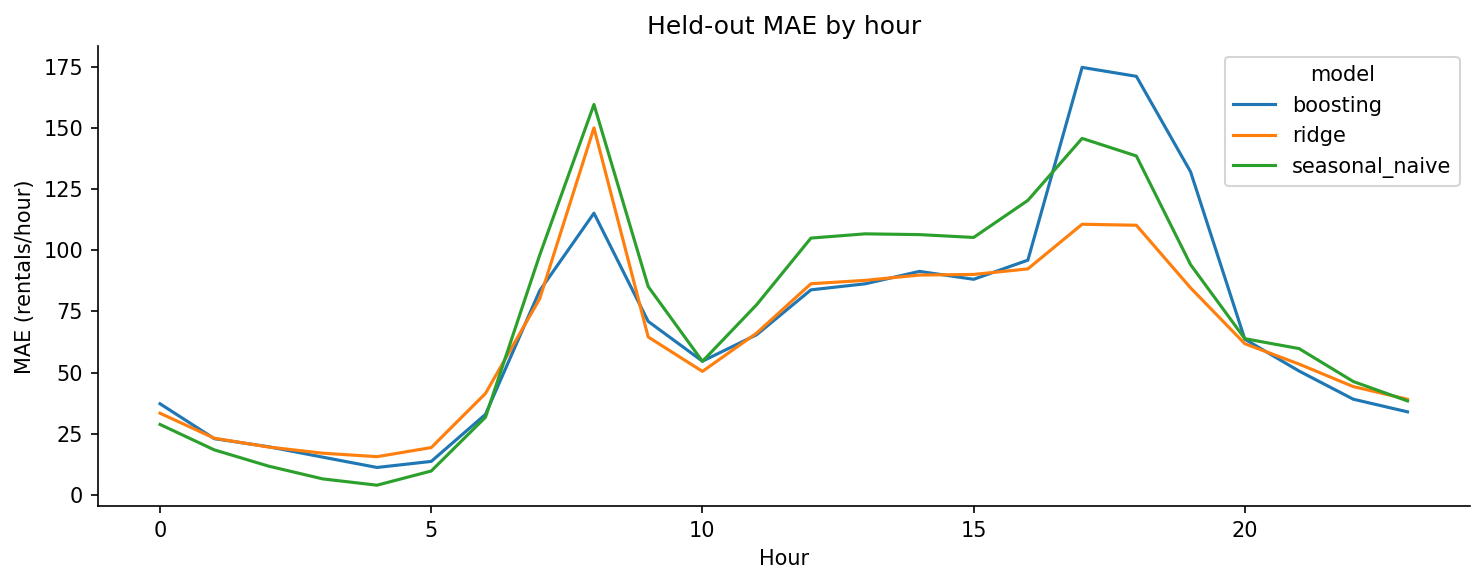

In [10]:
display(a['slices'])
boost_slices = a['slices'].query("model == 'boosting'")
worst = boost_slices.loc[boost_slices.MAE.idxmax()]
display(Markdown(f"Worst boosting slice by MAE: **{worst['dimension']} = {worst['slice']}**, n={int(worst['n'])}, MAE={worst['MAE']:.2f}, RMSE={worst['RMSE']:.2f}."))
display(Image(filename=str(ROOT/'visualizations/sliced_errors.png')))

## 10. Business decision and transparent money assumptions
Hypothetical daily decision: plan aggregate hourly rental-service capacity as `ceil(max(0, forecast))`.
This is a rental-throughput planning unit, not unique bicycles, a station allocation, or an optimized
staffing roster. Convert to staffing only after validating operational throughput constraints.
The same fixed rule is applied to both forecasts, without selecting an offset on test data.

Assume **$5 for each rental-unit of underplanned capacity** and **$1 for each excess planned unit**.
Proxy cost = 5 × max(actual − planned, 0) + 1 × max(planned − actual, 0), summed across identical test
hours. These are hypothetical assumptions, not verified operating costs. The sensitivity grid varies
shortage cost across $2/$5/$10 and excess cost across $0.50/$1/$2. It evaluates the fixed decisions;
it does not optimize an asymmetric-loss policy on the test set.

Counts record completed rentals. Stockouts, unavailable docks, weather cancellations, and unobserved
customers mean completed trips are an imperfect proxy for latent demand. Cost differences are
conditional historical scenarios, **not causal savings or evidence of deployment**. Point forecasts
optimized for MAE need not minimize asymmetric cost; a future cost-aware policy must be selected using
new training/calibration data, then evaluated on a new holdout.

,under_cost,excess_cost,seasonal_naive,boosting,proxy_cost_reduction
0,2.0,0.5,97961.5,61346.5,36615.0
1,2.0,1.0,127759.0,101301.0,26458.0
2,2.0,2.0,187354.0,181210.0,6144.0
3,5.0,0.5,200207.5,93434.5,106773.0
4,5.0,1.0,230005.0,133389.0,96616.0
5,5.0,2.0,289600.0,213298.0,76302.0
6,10.0,0.5,370617.5,146914.5,223703.0
7,10.0,1.0,400415.0,186869.0,213546.0
8,10.0,2.0,460010.0,266778.0,193232.0


Assumed-cost reduction versus seasonal baseline: $96,616.00 across 1302 common test hours.


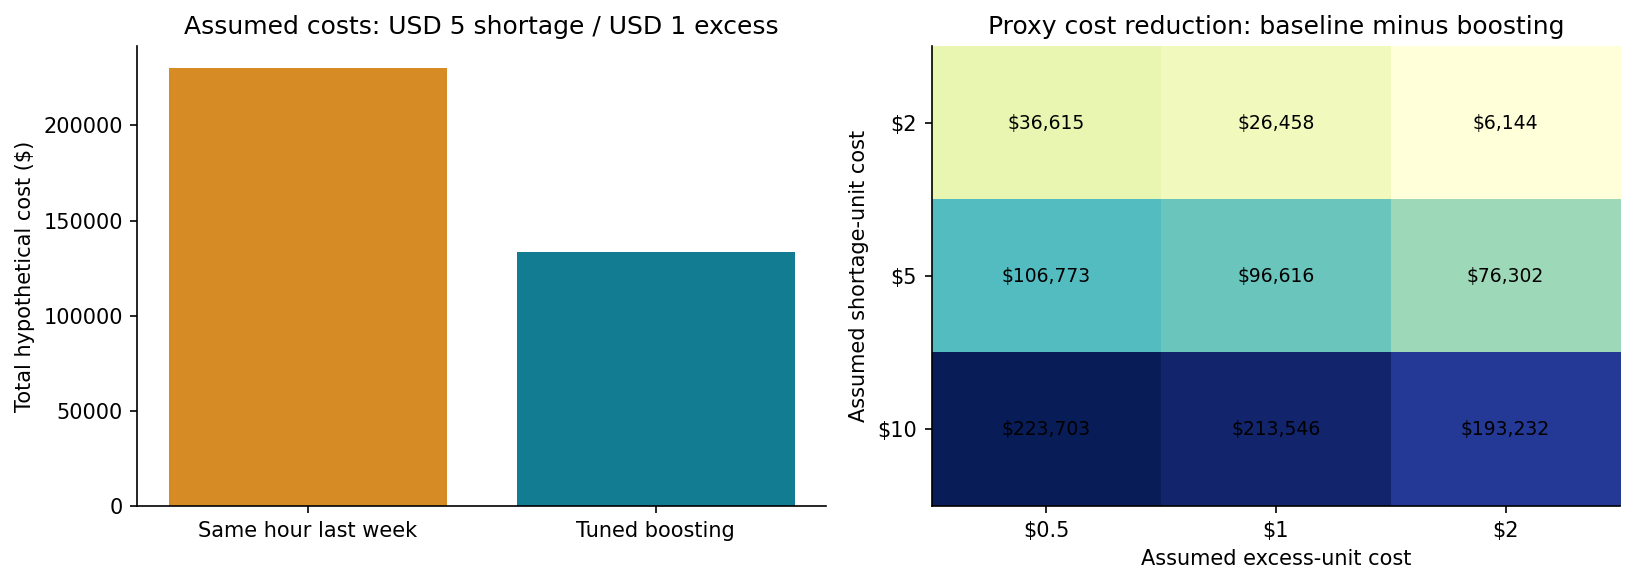

In [11]:
display(a['costs'])
business_plot(a['costs'])
base_cost = a['costs'].query('under_cost == 5 and excess_cost == 1').iloc[0]
print(f"Assumed-cost reduction versus seasonal baseline: ${base_cost.proxy_cost_reduction:,.2f} across {len(d['test'])} common test hours.")
display(Image(filename=str(ROOT/'visualizations/business_costs.png')))

## 11. Gurobi: from demand forecasts to shift assignments
This exploratory extension uses `gurobipy` mixed-integer optimization and Plotly visualizations.
The decision is six nonoverlapping four-hour shift assignment counts x[0]…x[5], starting at
00:00, 04:00, 08:00, 12:00, 16:00 and 20:00. Integer x[s] is between 0 and 20;
sum(x) is at most 48 worker-shift assignments (192 worker-hours), not 48 unique employees.

**Explicit assumptions:** 40 rental-service units per worker-hour; USD 20 hourly wage;
USD 5 per forecast shortage-unit; USD 1 per forecast excess-unit. For hour h,
capacity = 40 x[floor(h/4)]. Nonnegative shortage/excess variables satisfy
capacity + shortage − excess = forecast. Gurobi minimizes 80 sum(x) + 5 sum(shortage)
+ sum(excess). There are 54 variables (six integer) and 25 constraints. A valid Gurobi
license is needed; the small model was solved successfully using this environment's available license.
No license keys are included, and failure never produces invented solutions.

Each solver call accepts only the issued 24-hour forecast and fixed assumptions. Actual rentals
are used later to evaluate the frozen plan. The same model is solved for seasonal-naive, Ridge
and boosting forecasts. A fixed benchmark assigns eight workers to each shift. We report solver
status, bound and gap and require certified optimality. A brute-force small-case test independently
checks the objective.

Only complete days from the common forecast sample are evaluated: **48 days / 1,152 hours**;
eight partial days are excluded for every method, without filling observations. This is a different
sample and cost definition from the earlier point-capacity proxy. Nine cost scenarios revalue the
same plans; they do not retune plans on actuals. Capacity is hypothetical throughput, not bicycles,
station allocation or a labor-compliant individual roster. Shift overlap, breaks and labor rules
would need operational data. This decision extension was designed after forecast test scores were
known, so it is an **exploratory retrospective scenario**, requiring a fresh prospective evaluation.


,Optimization audit
assumptions,"{'throughput': 40.0, 'hourly_wage': 20.0, 'und..."
complete_days,48
evaluated_hours,1152
excluded_partial_days,8
optimal_solves,144
gurobi_version,13.0.3
interpretation,Exploratory retrospective scenario; assumption...


,wages,shortage_units,excess_units,total_cost
method,,,,
boosting,167600.0,15816.0,133782.0,380462.0
flat_staffing,184320.0,35208.0,186614.0,546974.0
ridge,154160.0,21271.0,112357.0,372872.0
seasonal_naive,155280.0,25480.0,118806.0,401486.0


,under_cost,excess_cost,method,fixed_plan_cost
0,2.0,0.5,boosting,266123.0
1,2.0,0.5,flat_staffing,348043.0
2,2.0,0.5,ridge,252880.5
3,2.0,0.5,seasonal_naive,265643.0
4,2.0,1.0,boosting,333014.0
5,2.0,1.0,flat_staffing,441350.0
6,2.0,1.0,ridge,309059.0
7,2.0,1.0,seasonal_naive,325046.0
8,2.0,2.0,boosting,466796.0
9,2.0,2.0,flat_staffing,627964.0


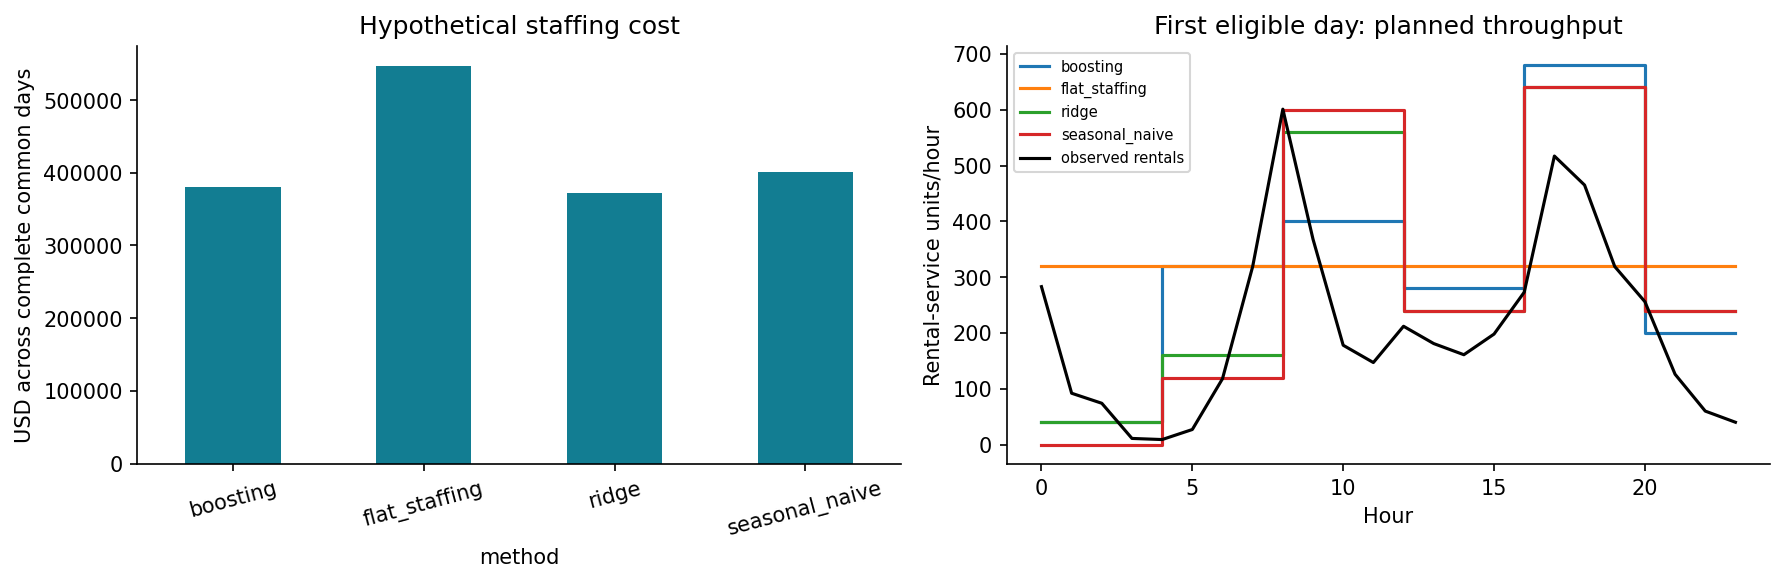

Interactive chart: visualizations/staffing_interactive.html


In [12]:
from bike_sharing import run_optimization
operations = run_optimization(a['predictions'])
display(pd.Series(operations['summary']).to_frame('Optimization audit'))
display(operations['totals'])
display(operations['sensitivity'])
display(Image(filename=str(ROOT/'visualizations/staffing_optimization.png')))
# Plotly output is a standalone interactive HTML file, including its JavaScript for offline use.
print('Interactive chart: visualizations/staffing_interactive.html')

## 12. Model card
The following concise card is generated from this execution, including the measured limitations.

In [13]:
from bike_sharing import model_card
card = model_card(d, a)
(ROOT/'reports/model_card.md').write_text(card)
display(Markdown(card))

# Model card — next-day hourly system-wide rentals
**Owner:** Anshuman; hypothetical operations manager is the decision owner.
**Intended use:** research prototype for aggregate hourly service-capacity and staffing planning at 11:59 PM for the next 24 hourly slots. Not station allocation or autonomous deployment.
**Data and target:** UCI Capital Bikeshare 2011–2012, 17,379 observed hours; target `cnt`, completed rentals. Fit 2011-01-08 23:00:00–2012-10-07 23:00:00 (15,195 rows); calibration 2012-10-08 00:00:00–2012-11-04 23:00:00; test 2012-11-05 00:00:00–2012-12-30 23:00:00 (1,302 comparable hours).
**Methods:** seasonal naive; fixed-alpha Ridge pipeline; HistGradientBoosting pipeline tuned on three training-only chronological folds. Calendar and pre-issuance demand features only; no target components or future observed weather. Daily lags update, model parameters stay frozen.
**Metrics:** baseline MAE/RMSE 71.95/119.50; Ridge 64.10/96.10; boosting 69.30/108.42 rentals/hour. Ridge has the lowest held-out MAE; complexity did not win.
**Error slices:** worst boosting slice: hour=17, MAE 174.65, RMSE 210.10, n=55. Test seasons are autumn/winter only; group errors are not individual fairness guarantees.
**Uncertainty:** MAPIE chronological calibration, nominal 90%, empirical 85.64%, mean width 251.42 rentals. Serial dependence and temporal shift undermine exchangeability guarantees; no conditional or station coverage claim.
**Known failure modes:** weather changes and exceptional events, trend shifts, commute peaks, missing history, recording delay, rental counts censoring unmet demand; no station inventories. SHAP is descriptive, not causal. Missing baseline hours narrow the scored population.
**Decision optimization:** Gurobi assigns six four-hour shifts under explicit throughput, wage and budget assumptions. Targets are used only for evaluation on 48 complete days; 144 optimal solves are recorded. This retrospective extension requires prospective validation; Plotly provides interactive daily cost comparisons.
**Deployment limits and monitoring:** do not deploy directly. Pilot against Ridge and seasonal naive; verify calendar and count latency. Monitor daily missingness, rolling weekly MAE/RMSE, commute errors, interval coverage/width, and proxy costs. Investigate sustained coverage below 90% or MAE above the concurrent baseline across two weeks; review drift and recalibrate/retrain chronologically before reconsidering deployment. Thresholds are proposed monitoring rules, not validated alarms.


## Authorship, AI assistance and reproducibility
**Anshuman — personal data science portfolio project.** OpenAI Codex was used to debug code,
resolve implementation issues, and assist with implementation, tests, analysis, visualizations,
documentation, and report drafting. Anshuman is responsible for reviewing and explaining the
methods, assumptions and conclusions. All reported numerical results come from executed code
on the public UCI dataset; AI-generated text is not evidence of model performance.

Source data: UCI Bike Sharing Dataset, Fanaee-T & Gama (2013),
[doi:10.1007/s13748-013-0040-3](https://doi.org/10.1007/s13748-013-0040-3).
See `data/README.md` for provenance and checksum validation.

Missing targets are preserved; no synthetic fallback or future observed weather is used.
SHAP describes the fitted model, not causal effects. This is a research prototype with
hypothetical planning scenarios; no production deployment or realized savings are claimed.
